# Assignment 7: Unsupervised Learning (PCA, k-Means, Hierarchical Clustering)
**Amari Ware** | DDS8555 Predictive Analysis | National University

Contents
1. ISLP Chapter 12, Conceptual Exercise 1 (k-means objective)
2. ISLP Chapter 12, Applied Exercise 9 (hierarchical clustering of `USArrests`)
3. Wine Data for Clustering (Kaggle): assumptions, PCA to 80% variance, k-means for several k, hierarchical clustering, interpretation

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
pd.set_option('display.precision', 3)
np.random.seed(1)

## 1. Conceptual Exercise 1

**(a) Prove Equation 12.18:**

$$\frac{1}{|C_k|}\sum_{i,i'\in C_k}\sum_{j=1}^{p}(x_{ij}-x_{i'j})^2 \;=\; 2\sum_{i\in C_k}\sum_{j=1}^{p}(x_{ij}-\bar{x}_{kj})^2, \qquad \bar{x}_{kj}=\frac{1}{|C_k|}\sum_{i\in C_k}x_{ij}.$$

*Proof.* Fix feature $j$ and write $n=|C_k|$ and $\bar x=\bar x_{kj}$. Add and subtract the centroid:

$$x_{ij}-x_{i'j}=(x_{ij}-\bar x)-(x_{i'j}-\bar x).$$

Squaring and summing over all ordered pairs $i,i'\in C_k$:

$$\sum_{i,i'}(x_{ij}-x_{i'j})^2=\sum_{i,i'}(x_{ij}-\bar x)^2+\sum_{i,i'}(x_{i'j}-\bar x)^2-2\sum_{i,i'}(x_{ij}-\bar x)(x_{i'j}-\bar x).$$

The first two terms each equal $n\sum_{i}(x_{ij}-\bar x)^2$, since each squared deviation is repeated once for each of the $n$ values of the other index. The cross term factors as $\big(\sum_i(x_{ij}-\bar x)\big)\big(\sum_{i'}(x_{i'j}-\bar x)\big)=0\cdot 0=0$, because deviations from a mean sum to zero. Therefore

$$\sum_{i,i'}(x_{ij}-x_{i'j})^2 = 2n\sum_{i\in C_k}(x_{ij}-\bar x)^2.$$

Dividing by $n=|C_k|$ and summing over $j=1,\dots,p$ gives Equation 12.18. $\blacksquare$

**(b) Why Algorithm 12.2 decreases objective 12.17 at each iteration.**

By (a), the objective $\sum_k W(C_k)$ equals $2\sum_k\sum_{i\in C_k}\lVert x_i-\bar x_k\rVert^2$, which is twice the total within-cluster sum of squared distances to the cluster centroids. Each iteration has two steps, and neither can increase this quantity:

* **Centroid step (2a).** With assignments held fixed, the vector $\mu$ that minimizes $\sum_{i\in C_k}\lVert x_i-\mu\rVert^2$ is the cluster mean (set the gradient $-2\sum_i(x_i-\mu)$ to zero). Replacing each centroid with its cluster mean therefore cannot increase the objective.
* **Assignment step (2b).** With centroids held fixed, assigning each observation to its *closest* centroid minimizes that observation's term $\lVert x_i-\mu_k\rVert^2$. Any reassignment that happens strictly lowers that observation's contribution, so the objective cannot increase.

The objective is bounded below by zero and there are finitely many partitions of $n$ observations into $K$ clusters. A monotonically non-increasing sequence over a finite set must stop changing, so the algorithm converges. It converges to a **local**, not necessarily global, optimum, which is why k-means is run from multiple random starts (`n_init` below).

In [2]:
# Numerical check of identity 12.18 on a random cluster
X_chk = np.random.randn(25, 4)
lhs = sum(((xi - xj)**2).sum() for xi in X_chk for xj in X_chk) / len(X_chk)
rhs = 2 * ((X_chk - X_chk.mean(0))**2).sum()
print(f"LHS = {lhs:.6f}, RHS = {rhs:.6f}, equal: {np.isclose(lhs, rhs)}")

LHS = 153.799625, RHS = 153.799625, equal: True


## 2. Applied Exercise 9: Hierarchical clustering of `USArrests`
Data: 50 states with `Murder`, `Assault`, and `Rape` (arrests per 100,000 residents) and `UrbanPop` (percent urban).

In [3]:
usa = pd.read_csv('USArrests.csv', index_col=0)
print(usa.describe().T[['mean','std','min','max']])

             mean     std   min    max
Murder      7.788   4.356   0.8   17.4
Assault   170.760  83.338  45.0  337.0
UrbanPop   65.540  14.475  32.0   91.0
Rape       21.232   9.366   7.3   46.0


**(a) Complete linkage, Euclidean distance, unscaled data**

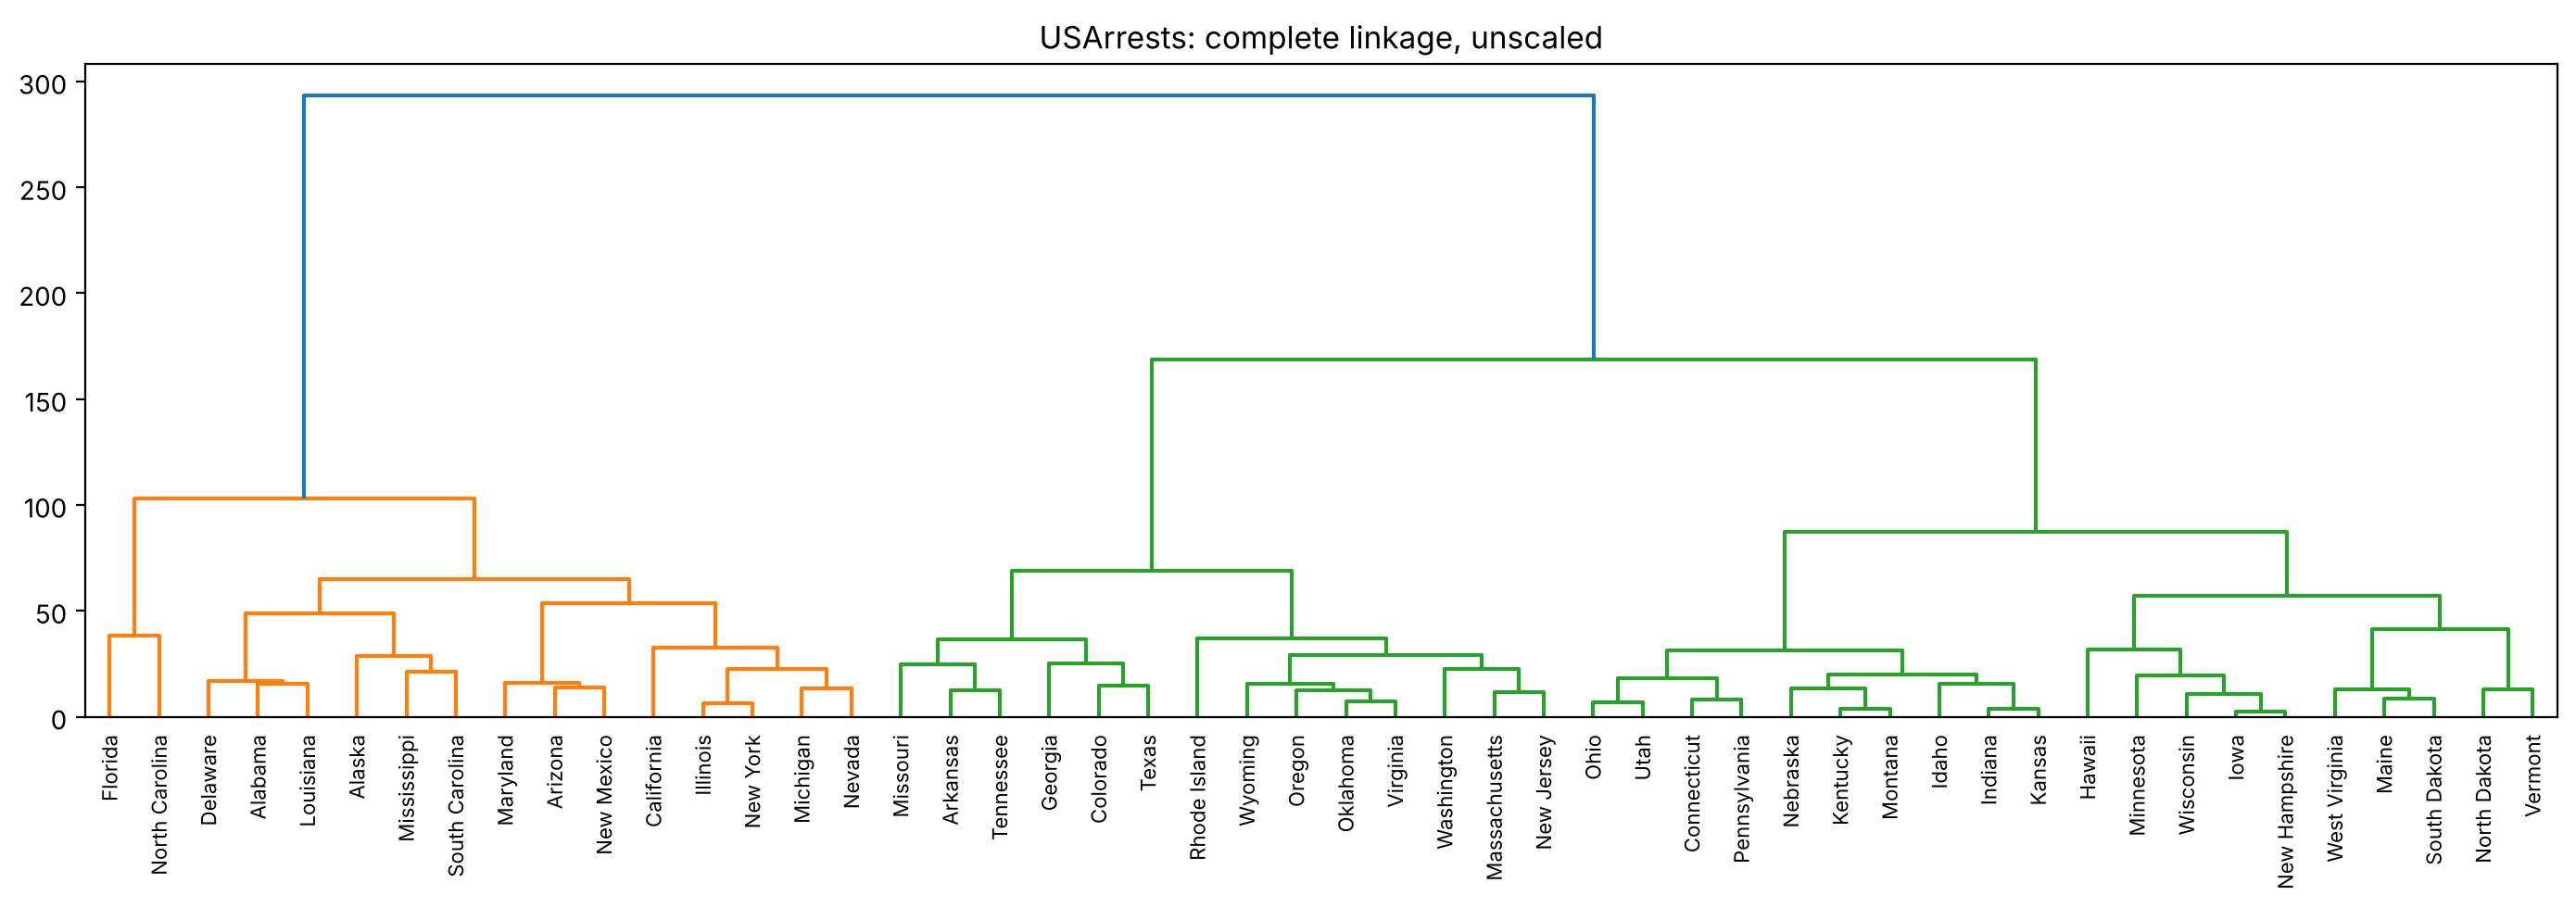

In [4]:
hc_raw = linkage(usa.values, method='complete', metric='euclidean')
fig, ax = plt.subplots(figsize=(14, 5))
dendrogram(hc_raw, labels=usa.index.tolist(), leaf_rotation=90, color_threshold=None, ax=ax)
ax.set_title('USArrests: complete linkage, unscaled'); plt.tight_layout(); plt.show()

**(b) Cut the dendrogram into three clusters**

In [5]:
usa['cluster_raw'] = fcluster(hc_raw, t=3, criterion='maxclust')
for k, g in usa.groupby('cluster_raw'):
    print(f"Cluster {k} ({len(g)} states): {', '.join(g.index)}\n")
print(usa.groupby('cluster_raw')[['Murder','Assault','UrbanPop','Rape']].mean())

Cluster 1 (16 states): Alabama, Alaska, Arizona, California, Delaware, Florida, Illinois, Louisiana, Maryland, Michigan, Mississippi, Nevada, New Mexico, New York, North Carolina, South Carolina

Cluster 2 (14 states): Arkansas, Colorado, Georgia, Massachusetts, Missouri, New Jersey, Oklahoma, Oregon, Rhode Island, Tennessee, Texas, Virginia, Washington, Wyoming

Cluster 3 (20 states): Connecticut, Hawaii, Idaho, Indiana, Iowa, Kansas, Kentucky, Maine, Minnesota, Montana, Nebraska, New Hampshire, North Dakota, Ohio, Pennsylvania, South Dakota, Utah, Vermont, West Virginia, Wisconsin

             Murder  Assault  UrbanPop    Rape
cluster_raw                                   
1            11.812  272.562    68.312  28.375
2             8.214  173.286    70.643  22.843
3             4.270   87.550    59.750  14.390


**(c) Complete linkage after scaling each variable to standard deviation one**

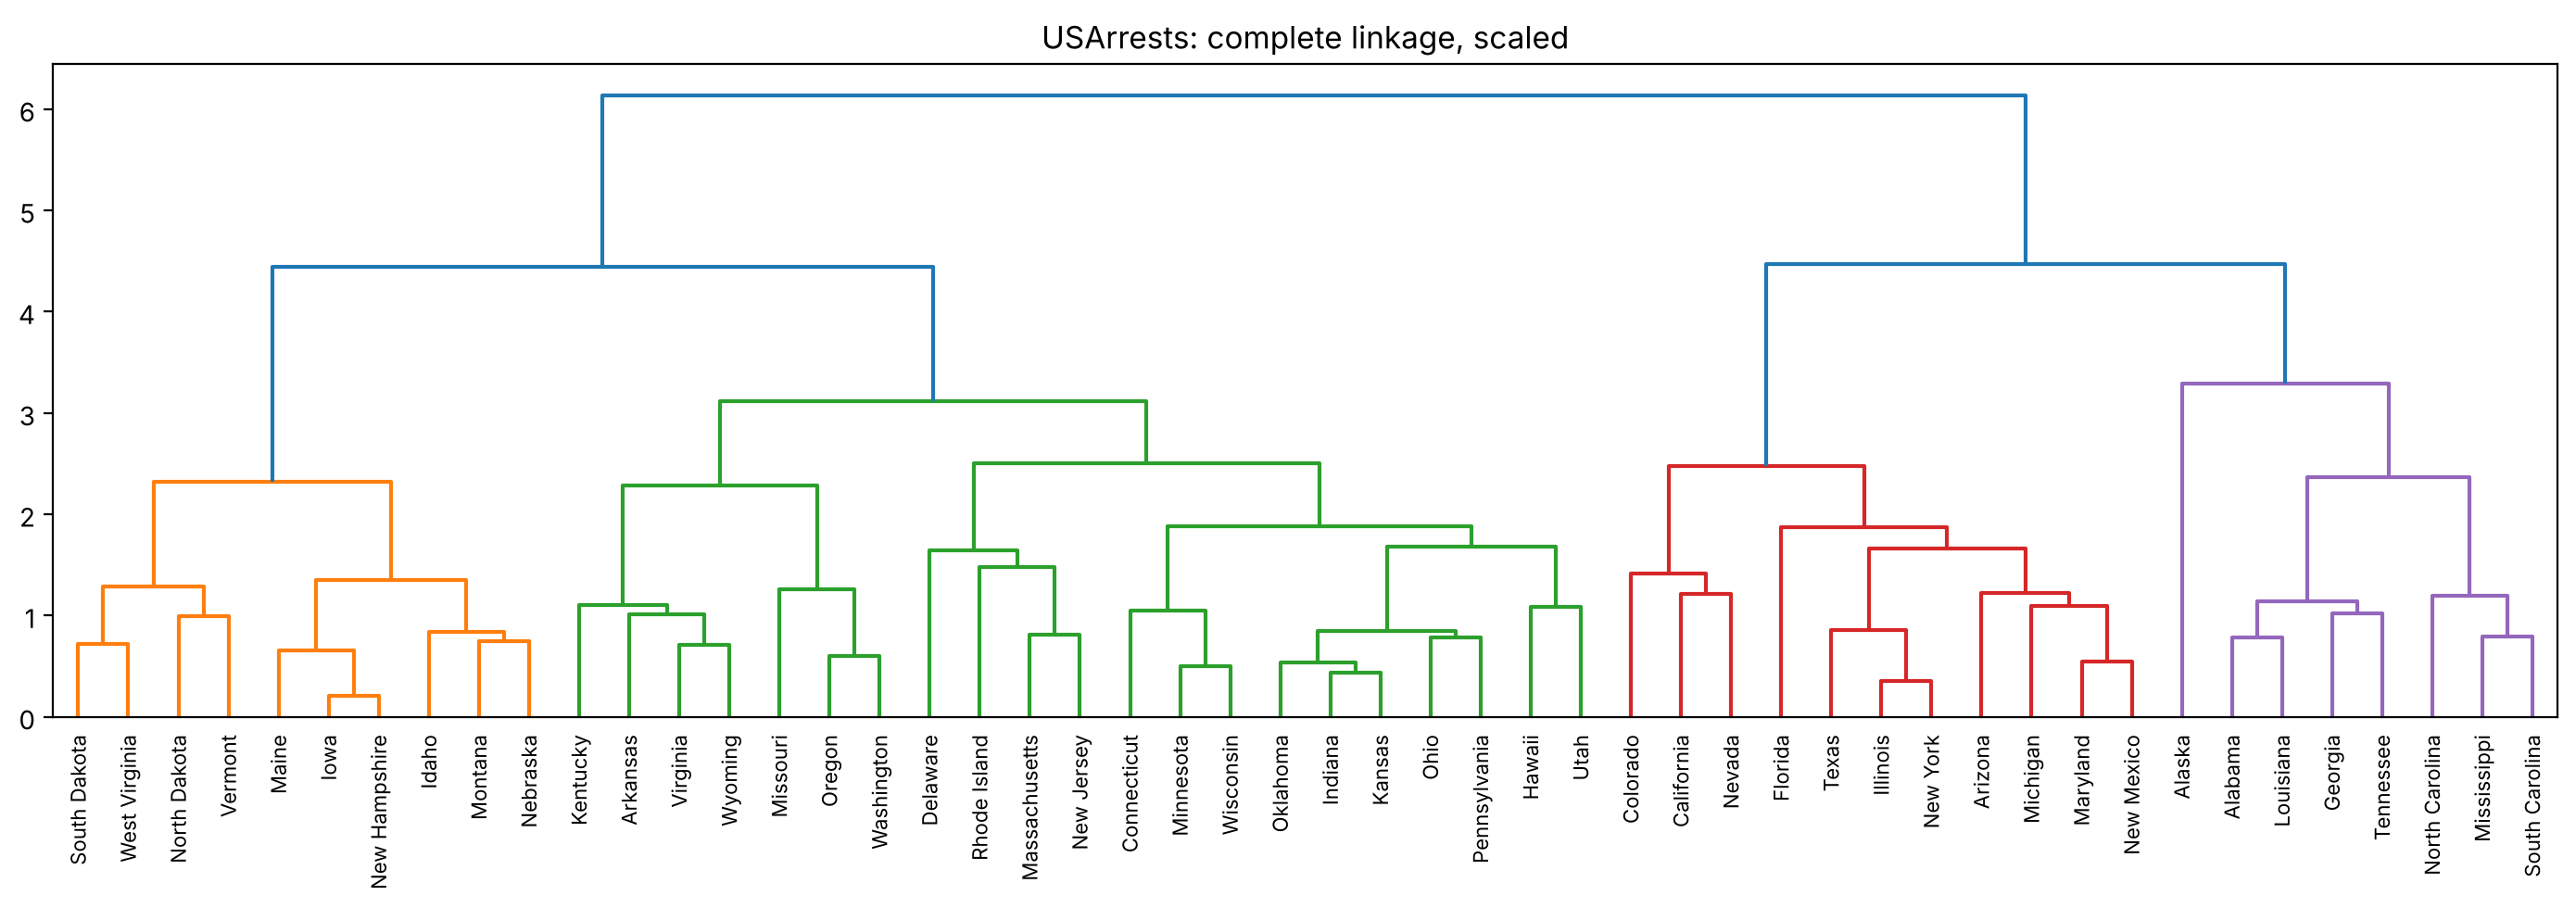

Cluster 1 (31 states): Arkansas, Connecticut, Delaware, Hawaii, Idaho, Indiana, Iowa, Kansas, Kentucky, Maine, Massachusetts, Minnesota, Missouri, Montana, Nebraska, New Hampshire, New Jersey, North Dakota, Ohio, Oklahoma, Oregon, Pennsylvania, Rhode Island, South Dakota, Utah, Vermont, Virginia, Washington, West Virginia, Wisconsin, Wyoming

Cluster 2 (11 states): Arizona, California, Colorado, Florida, Illinois, Maryland, Michigan, Nevada, New Mexico, New York, Texas

Cluster 3 (8 states): Alabama, Alaska, Georgia, Louisiana, Mississippi, North Carolina, South Carolina, Tennessee

scaled     1  2  3
unscaled          
1          1  9  6
2         10  2  2
3         20  0  0
Adjusted Rand index, unscaled vs scaled: 0.368


In [6]:
Z_usa = StandardScaler().fit_transform(usa[['Murder','Assault','UrbanPop','Rape']])
hc_sc = linkage(Z_usa, method='complete', metric='euclidean')
fig, ax = plt.subplots(figsize=(14, 5))
dendrogram(hc_sc, labels=usa.index.tolist(), leaf_rotation=90, ax=ax)
ax.set_title('USArrests: complete linkage, scaled'); plt.tight_layout(); plt.show()
usa['cluster_scaled'] = fcluster(hc_sc, t=3, criterion='maxclust')
for k, g in usa.groupby('cluster_scaled'):
    print(f"Cluster {k} ({len(g)} states): {', '.join(g.index)}\n")
print(pd.crosstab(usa['cluster_raw'], usa['cluster_scaled'], rownames=['unscaled'], colnames=['scaled']))
print('Adjusted Rand index, unscaled vs scaled:', round(adjusted_rand_score(usa['cluster_raw'], usa['cluster_scaled']), 3))

In [7]:
print('Variance of each raw variable:')
print(usa[['Murder','Assault','UrbanPop','Rape']].var().round(1))

Variance of each raw variable:
Murder        19.0
Assault     6945.2
UrbanPop     209.5
Rape          87.7
dtype: float64


**(d) Effect of scaling, and whether to scale.**

Unscaled, `Assault` has a variance of several thousand while the other variables have variances in the tens to low hundreds. Euclidean distances are therefore driven almost entirely by `Assault`, and the unscaled three-cluster solution is essentially a split of states into high, medium, and low assault rates. After scaling, all four variables contribute equally, so `UrbanPop`, `Murder`, and `Rape` reshape the tree. The cross-tabulation and the adjusted Rand index above show that many states change cluster.

**The variables should be scaled.** They are measured in different units (arrests per 100,000 versus a percentage), and the size of `Assault`'s variance reflects how common assault arrests are, not that it matters more. Without scaling, the clustering silently weights variables by their measurement scale. Standardizing lets each variable contribute in proportion to its relative variation, which is the defensible default when units differ (James et al., 2023).

## 3. Wine Data for Clustering

The Kaggle *Wine Dataset for Clustering* contains 178 Italian wines measured on 13 chemical properties, with the cultivar label removed. It is the UCI wine data described by Aeberhard et al. (1994). The notebook reads `wine-clustering.csv` downloaded from Kaggle. If that file is not present, it loads the identical UCI data that ships with scikit-learn and renames the columns to match. Because scikit-learn also includes the cultivar labels, we can check the clusters against the known three cultivars **after** the unsupervised analysis, without using the labels to fit anything.

In [8]:
import os
from sklearn.datasets import load_wine
kaggle_cols = ['Alcohol','Malic_Acid','Ash','Ash_Alcanity','Magnesium','Total_Phenols','Flavanoids',
               'Nonflavanoid_Phenols','Proanthocyanins','Color_Intensity','Hue','OD280','Proline']
ref = load_wine(as_frame=True)
ref_X = ref.data.copy(); ref_X.columns = kaggle_cols
if os.path.exists('wine-clustering.csv'):
    wine = pd.read_csv('wine-clustering.csv')
    source = 'Kaggle wine-clustering.csv'
else:
    wine = ref_X.copy()
    source = 'scikit-learn copy of the same UCI data'
print('Source:', source, '| shape:', wine.shape, '| missing values:', int(wine.isna().sum().sum()))
same = wine.shape == ref_X.shape and np.allclose(wine.values, ref_X.values)
cultivar = ref.target.values if same else None
print('Rows match the labeled UCI data (labels usable for after-the-fact validation):', same)
wine.describe().T[['mean','std','min','max']]

Source: Kaggle wine-clustering.csv | shape: (178, 13) | missing values: 0
Rows match the labeled UCI data (labels usable for after-the-fact validation): True


,mean,std,min,max
Alcohol,13.001,0.812,11.03,14.83
Malic_Acid,2.336,1.117,0.74,5.80
Ash,2.367,0.274,1.36,3.23
Ash_Alcanity,19.495,3.340,10.60,30.00
Magnesium,99.742,14.282,70.00,162.00
Total_Phenols,2.295,0.626,0.98,3.88
Flavanoids,2.029,0.999,0.34,5.08
Nonflavanoid_Phenols,0.362,0.124,0.13,0.66
Proanthocyanins,1.591,0.572,0.41,3.58
Color_Intensity,5.058,2.318,1.28,13.00


### 3.1 Investigating assumptions

**PCA assumptions:** the variables are continuous and linearly related, there are enough correlations to make dimension reduction worthwhile, the scales are comparable (otherwise standardize), and there are no extreme outliers dominating the variance. **k-means assumptions:** clusters are roughly spherical with similar spread, features are on comparable scales, and outliers are limited, since means are sensitive to them. **Hierarchical clustering assumptions:** results depend on the distance metric and the linkage choice, and the tree should faithfully represent the original distances (checked with the cophenetic correlation).

Proline            99166.72
Magnesium            203.99
Ash_Alcanity          11.15
Color_Intensity        5.37
Malic_Acid             1.25
dtype: float64


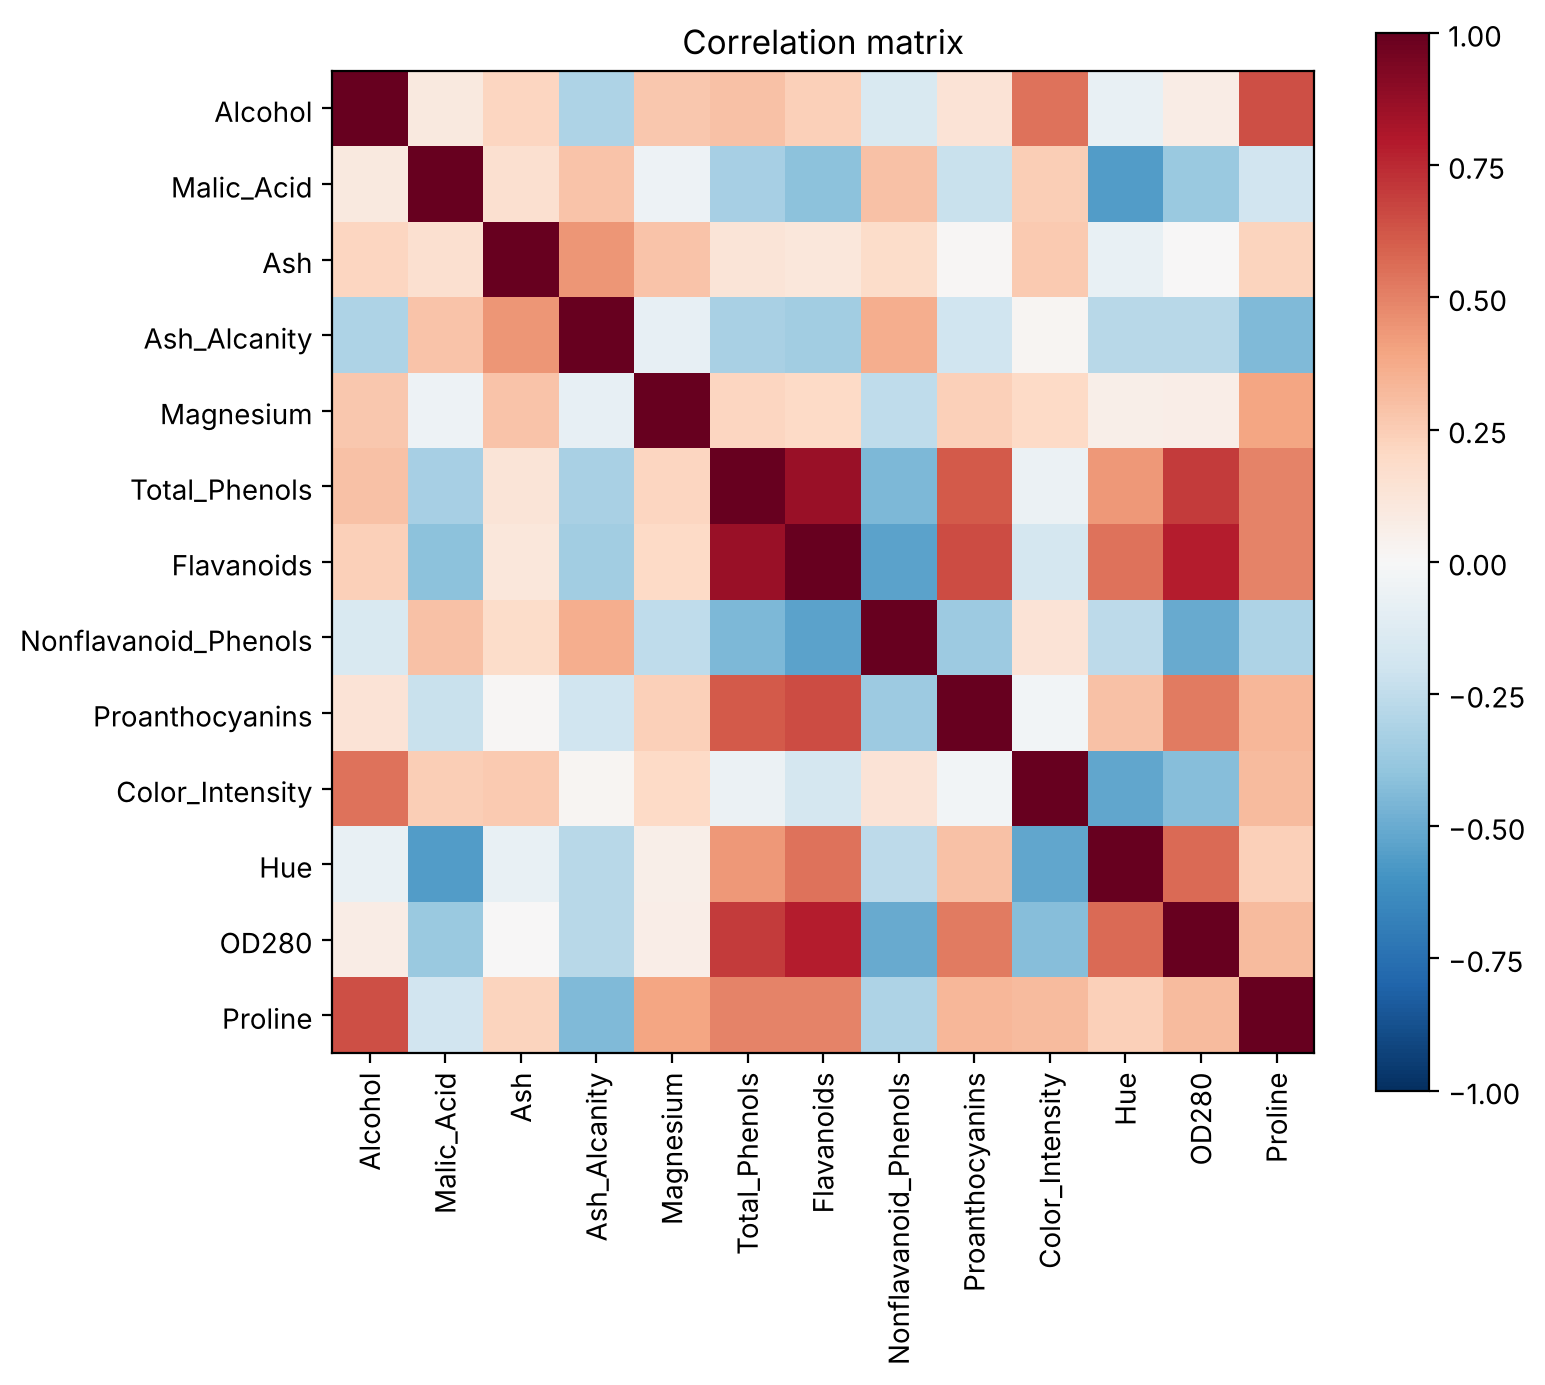

Share of |r| > 0.5: 0.083
Strongest pairs:
Total_Phenols  Flavanoids         0.865
Flavanoids     OD280              0.787
Total_Phenols  OD280              0.700
Flavanoids     Proanthocyanins    0.653
Alcohol        Proline            0.644
dtype: float64


In [9]:
# Scale differences: Proline and Magnesium dwarf the other variables
print(wine.var().sort_values(ascending=False).round(2).head(5))
# Correlation structure
R = wine.corr()
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(R, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(13)); ax.set_xticklabels(R.columns, rotation=90); ax.set_yticks(range(13)); ax.set_yticklabels(R.columns)
plt.colorbar(im); ax.set_title('Correlation matrix'); plt.tight_layout(); plt.show()
upper = R.where(np.triu(np.ones(R.shape), 1).astype(bool)).stack()
print('Share of |r| > 0.5:', round((upper.abs() > 0.5).mean(), 3))
print('Strongest pairs:'); print(upper.abs().sort_values(ascending=False).head(5).round(3))

In [10]:
# Bartlett's test of sphericity and Kaiser-Meyer-Olkin (KMO) sampling adequacy
n, p = wine.shape
chi2 = -(n - 1 - (2*p + 5)/6) * np.log(np.linalg.det(R))
dof = p*(p-1)/2
print(f"Bartlett: chi2 = {chi2:.1f}, df = {dof:.0f}, p = {stats.chi2.sf(chi2, dof):.2e}")
Rinv = np.linalg.inv(R)
partial = -Rinv / np.sqrt(np.outer(np.diag(Rinv), np.diag(Rinv)))
np.fill_diagonal(partial, 0); r2 = R.values.copy(); np.fill_diagonal(r2, 0)
kmo = (r2**2).sum() / ((r2**2).sum() + (partial**2).sum())
print(f"KMO overall = {kmo:.3f}")

Bartlett: chi2 = 1317.2, df = 78, p = 2.47e-224
KMO overall = 0.779


                      skew  Shapiro_p
Alcohol              -0.05  2.000e-02
Malic_Acid            1.03  0.000e+00
Ash                  -0.18  3.870e-02
Ash_Alcanity          0.21  2.639e-01
Magnesium             1.09  0.000e+00
Total_Phenols         0.09  4.400e-03
Flavanoids            0.03  0.000e+00
Nonflavanoid_Phenols  0.45  1.000e-04
Proanthocyanins       0.51  1.450e-02
Color_Intensity       0.86  0.000e+00
Hue                   0.02  1.740e-02
OD280                -0.30  0.000e+00
Proline               0.76  0.000e+00
Observations with any |z| > 3: 10 of 178


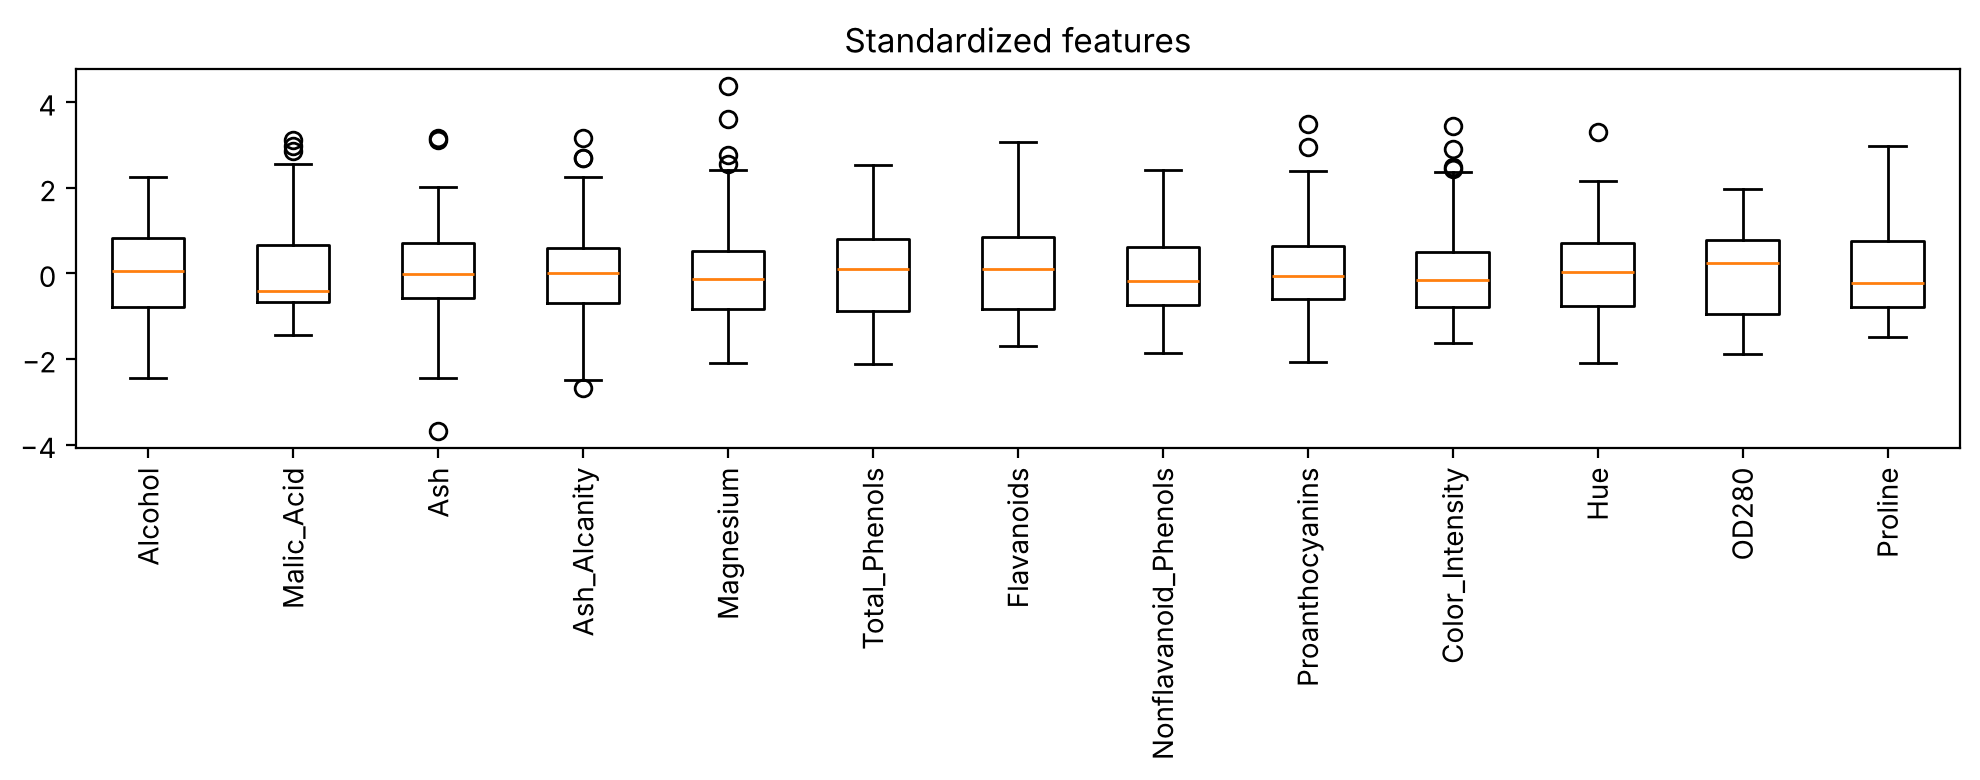

In [11]:
# Normality, skewness and outliers on standardized data
Z = StandardScaler().fit_transform(wine)
skew = pd.Series(stats.skew(wine), index=wine.columns).round(2)
sw_p = pd.Series([stats.shapiro(wine[c]).pvalue for c in wine.columns], index=wine.columns)
print(pd.DataFrame({'skew': skew, 'Shapiro_p': sw_p.round(4)}))
print('Observations with any |z| > 3:', int((np.abs(Z) > 3).any(axis=1).sum()), 'of', n)
fig, ax = plt.subplots(figsize=(10, 4)); ax.boxplot(Z); ax.set_xticks(range(1, p+1)); ax.set_xticklabels(wine.columns, rotation=90)
ax.set_title('Standardized features'); plt.tight_layout(); plt.show()

**Assumption findings.** Variances differ by orders of magnitude (`Proline` in the hundreds of thousands, `Hue` below 0.1), so all analyses use standardized variables. Without that, PCA and Euclidean distances would essentially be `Proline`. The correlation matrix shows a tightly correlated phenolic block (`Total_Phenols` with `Flavanoids`, r = 0.87; `Flavanoids` with `OD280`, r = 0.79) plus `Alcohol` with `Proline` (r = 0.64). Bartlett's test strongly rejects an identity correlation matrix (chi-square = 1317.2, df = 78, p < .001), and the overall KMO of 0.78 indicates the data are well suited to dimension reduction. Most variables fail Shapiro-Wilk tests, and `Malic_Acid` and `Magnesium` are right-skewed (skew of about 1). PCA does not require normality for description, but skewness and the 10 wines with at least one |z| > 3 can inflate variance, so the outliers are retained (they are plausible chemistry, not errors) and their influence is noted.

### 3.2 Principal component analysis: retain 80% of the variance

      eigenvalue    PVE  cumulative
PC1        4.732  0.362       0.362
PC2        2.511  0.192       0.554
PC3        1.454  0.111       0.665
PC4        0.924  0.071       0.736
PC5        0.858  0.066       0.802
PC6        0.645  0.049       0.851
PC7        0.554  0.042       0.893
PC8        0.350  0.027       0.920
PC9        0.291  0.022       0.942
PC10       0.252  0.019       0.962
PC11       0.227  0.017       0.979
PC12       0.170  0.013       0.992
PC13       0.104  0.008       1.000

Components needed for >= 80% of variance: 5 (cumulative = 0.802)


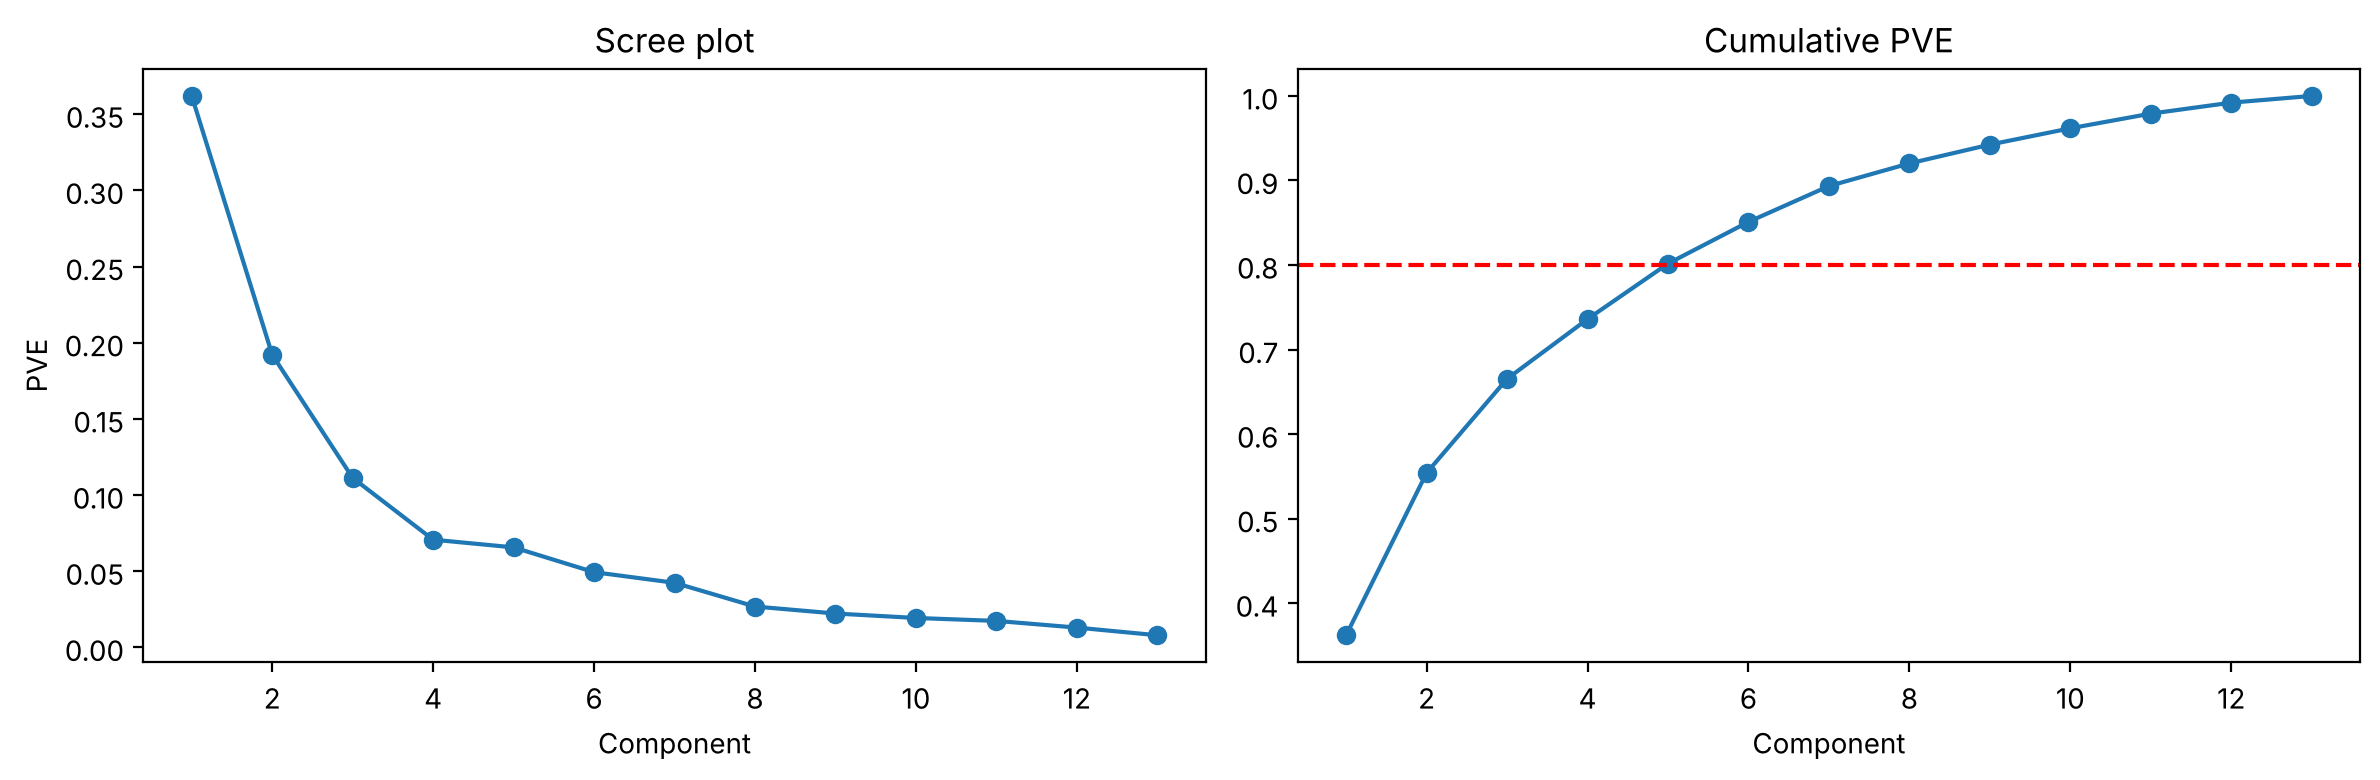

In [12]:
pca_full = PCA().fit(Z)
evr = pca_full.explained_variance_ratio_; cum = evr.cumsum()
n80 = int(np.argmax(cum >= 0.80) + 1)
print(pd.DataFrame({'eigenvalue': pca_full.explained_variance_.round(3), 'PVE': evr.round(3), 'cumulative': cum.round(3)},
                   index=[f'PC{i+1}' for i in range(p)]))
print(f"\nComponents needed for >= 80% of variance: {n80} (cumulative = {cum[n80-1]:.3f})")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(1, p+1), evr, 'o-'); ax[0].set_title('Scree plot'); ax[0].set_xlabel('Component'); ax[0].set_ylabel('PVE')
ax[1].plot(range(1, p+1), cum, 'o-'); ax[1].axhline(0.8, ls='--', c='r'); ax[1].set_title('Cumulative PVE'); ax[1].set_xlabel('Component')
plt.tight_layout(); plt.show()

In [13]:
pca = PCA(n_components=n80).fit(Z)
scores = pca.transform(Z)
loadings = pd.DataFrame(pca.components_.T, index=wine.columns, columns=[f'PC{i+1}' for i in range(n80)])
print(loadings.round(2))
for pc in loadings.columns[:3]:
    top = loadings[pc].abs().sort_values(ascending=False).head(4).index
    print(f"{pc} driven by: " + ', '.join(f"{v} ({loadings.loc[v, pc]:+.2f})" for v in top))

                       PC1   PC2   PC3   PC4   PC5
Alcohol               0.14  0.48 -0.21 -0.02 -0.27
Malic_Acid           -0.25  0.22  0.09  0.54  0.04
Ash                  -0.00  0.32  0.63 -0.21 -0.14
Ash_Alcanity         -0.24 -0.01  0.61  0.06  0.07
Magnesium             0.14  0.30  0.13 -0.35  0.73
Total_Phenols         0.39  0.07  0.15  0.20 -0.15
Flavanoids            0.42 -0.00  0.15  0.15 -0.11
Nonflavanoid_Phenols -0.30  0.03  0.17 -0.20 -0.50
Proanthocyanins       0.31  0.04  0.15  0.40  0.14
Color_Intensity      -0.09  0.53 -0.14  0.07 -0.08
Hue                   0.30 -0.28  0.09 -0.43 -0.17
OD280                 0.38 -0.16  0.17  0.18 -0.10
Proline               0.29  0.36 -0.13 -0.23 -0.16
PC1 driven by: Flavanoids (+0.42), Total_Phenols (+0.39), OD280 (+0.38), Proanthocyanins (+0.31)
PC2 driven by: Color_Intensity (+0.53), Alcohol (+0.48), Proline (+0.36), Ash (+0.32)
PC3 driven by: Ash (+0.63), Ash_Alcanity (+0.61), Alcohol (-0.21), Nonflavanoid_Phenols (+0.17)


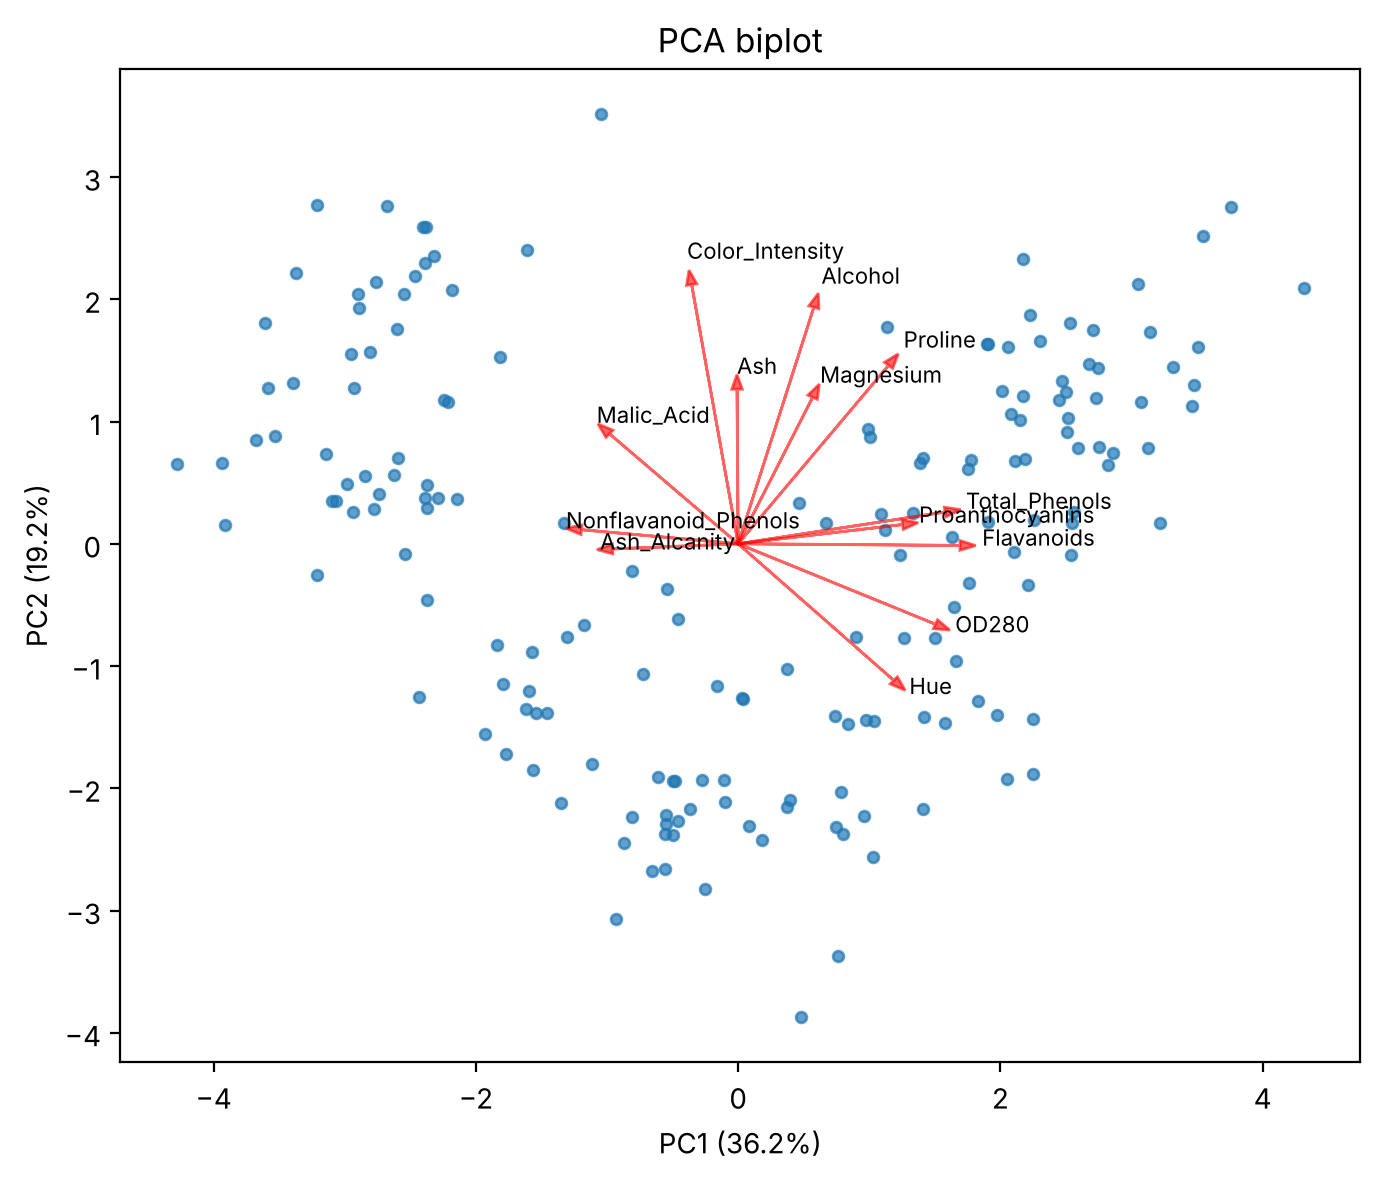

In [14]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(scores[:, 0], scores[:, 1], s=15, alpha=.7)
for v in wine.columns:
    ax.arrow(0, 0, loadings.loc[v, 'PC1']*4, loadings.loc[v, 'PC2']*4, color='r', alpha=.6, head_width=.08)
    ax.text(loadings.loc[v, 'PC1']*4.4, loadings.loc[v, 'PC2']*4.4, v, fontsize=8)
ax.set_xlabel(f'PC1 ({evr[0]:.1%})'); ax.set_ylabel(f'PC2 ({evr[1]:.1%})'); ax.set_title('PCA biplot')
plt.tight_layout(); plt.show()

### 3.3 k-means on the retained components for k = 2 to 8

        WSS  silhouette  Calinski_Harabasz  Davies_Bouldin  min_cluster_size
k                                                                           
2  1201.126       0.324             95.805           1.278                88
3   825.021       0.369            109.233           1.093                51
4   723.936       0.326             90.615           1.419                33
5   654.584       0.318             79.311           1.284                22
6   600.601       0.281             71.844           1.291                13
7   555.569       0.222             66.657           1.448                14
8   511.804       0.231             63.734           1.362                 5


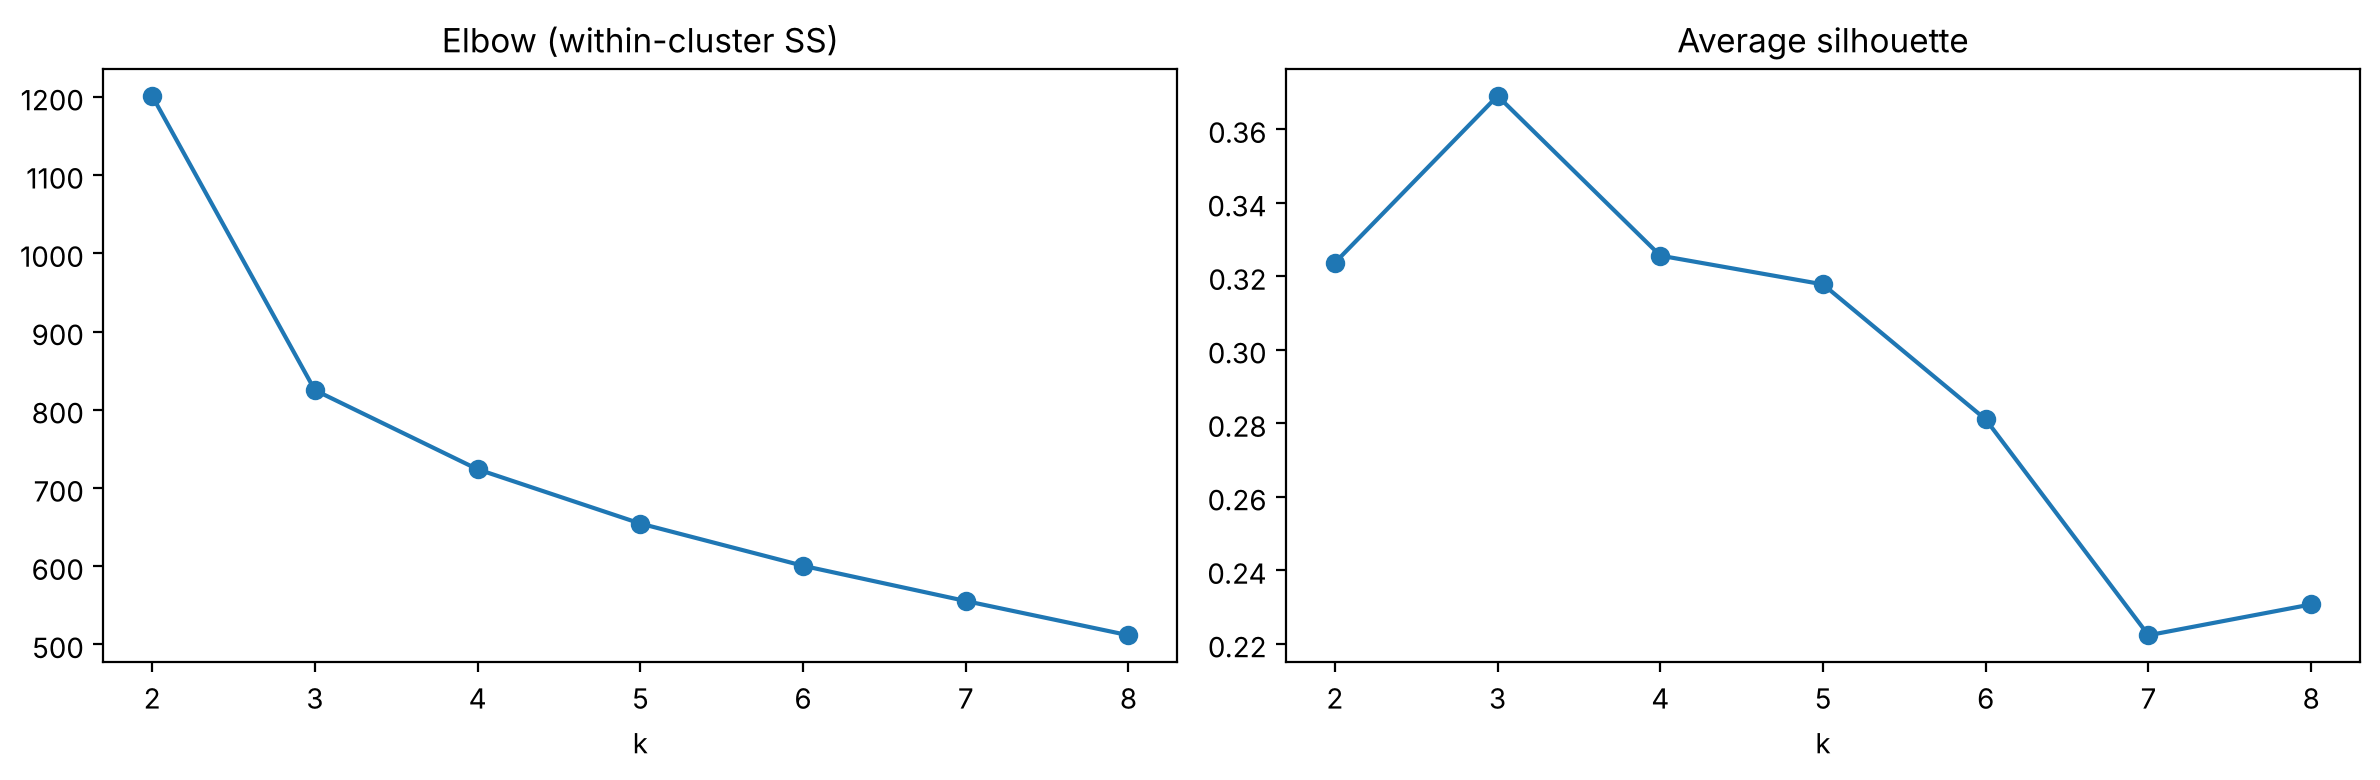

k with highest silhouette: 3


In [15]:
rows, fits = [], {}
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=50, random_state=1).fit(scores)
    fits[k] = km
    rows.append({'k': k, 'WSS': km.inertia_, 'silhouette': silhouette_score(scores, km.labels_),
                 'Calinski_Harabasz': calinski_harabasz_score(scores, km.labels_),
                 'Davies_Bouldin': davies_bouldin_score(scores, km.labels_),
                 'min_cluster_size': np.bincount(km.labels_).min()})
km_eval = pd.DataFrame(rows).set_index('k'); print(km_eval.round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(km_eval.index, km_eval.WSS, 'o-'); ax[0].set_title('Elbow (within-cluster SS)'); ax[0].set_xlabel('k')
ax[1].plot(km_eval.index, km_eval.silhouette, 'o-'); ax[1].set_title('Average silhouette'); ax[1].set_xlabel('k')
plt.tight_layout(); plt.show()
best_k = int(km_eval.silhouette.idxmax()); print('k with highest silhouette:', best_k)

In [16]:
# Stability across random starts, and the k = 3 solution
k3_runs = [KMeans(n_clusters=3, n_init=1, random_state=s).fit(scores) for s in range(20)]
print('k=3 WSS across 20 single random starts: min %.1f, max %.1f' % (min(m.inertia_ for m in k3_runs), max(m.inertia_ for m in k3_runs)))
km3 = fits[3]; lab_km = km3.labels_
print('Cluster sizes:', np.bincount(lab_km))
print('Within-cluster spread (mean squared distance to centroid):',
      [round(((scores[lab_km == c] - km3.cluster_centers_[c])**2).sum(1).mean(), 2) for c in range(3)])
profile = wine.assign(cluster=lab_km).groupby('cluster').mean().T
print(profile.round(2))

k=3 WSS across 20 single random starts: min 825.0, max 827.6
Cluster sizes: [51 65 62]
Within-cluster spread (mean squared distance to centroid): [np.float64(3.69), np.float64(5.9), np.float64(4.09)]
cluster                    0       1        2
Alcohol                13.13   12.25    13.68
Malic_Acid              3.31    1.90     2.00
Ash                     2.42    2.23     2.47
Ash_Alcanity           21.24   20.06    17.46
Magnesium              98.67   92.74   107.97
Total_Phenols           1.68    2.25     2.85
Flavanoids              0.82    2.05     3.00
Nonflavanoid_Phenols    0.45    0.36     0.29
Proanthocyanins         1.15    1.62     1.92
Color_Intensity         7.23    2.97     5.45
Hue                     0.69    1.06     1.07
OD280                   1.70    2.80     3.16
Proline               619.06  510.17  1100.23


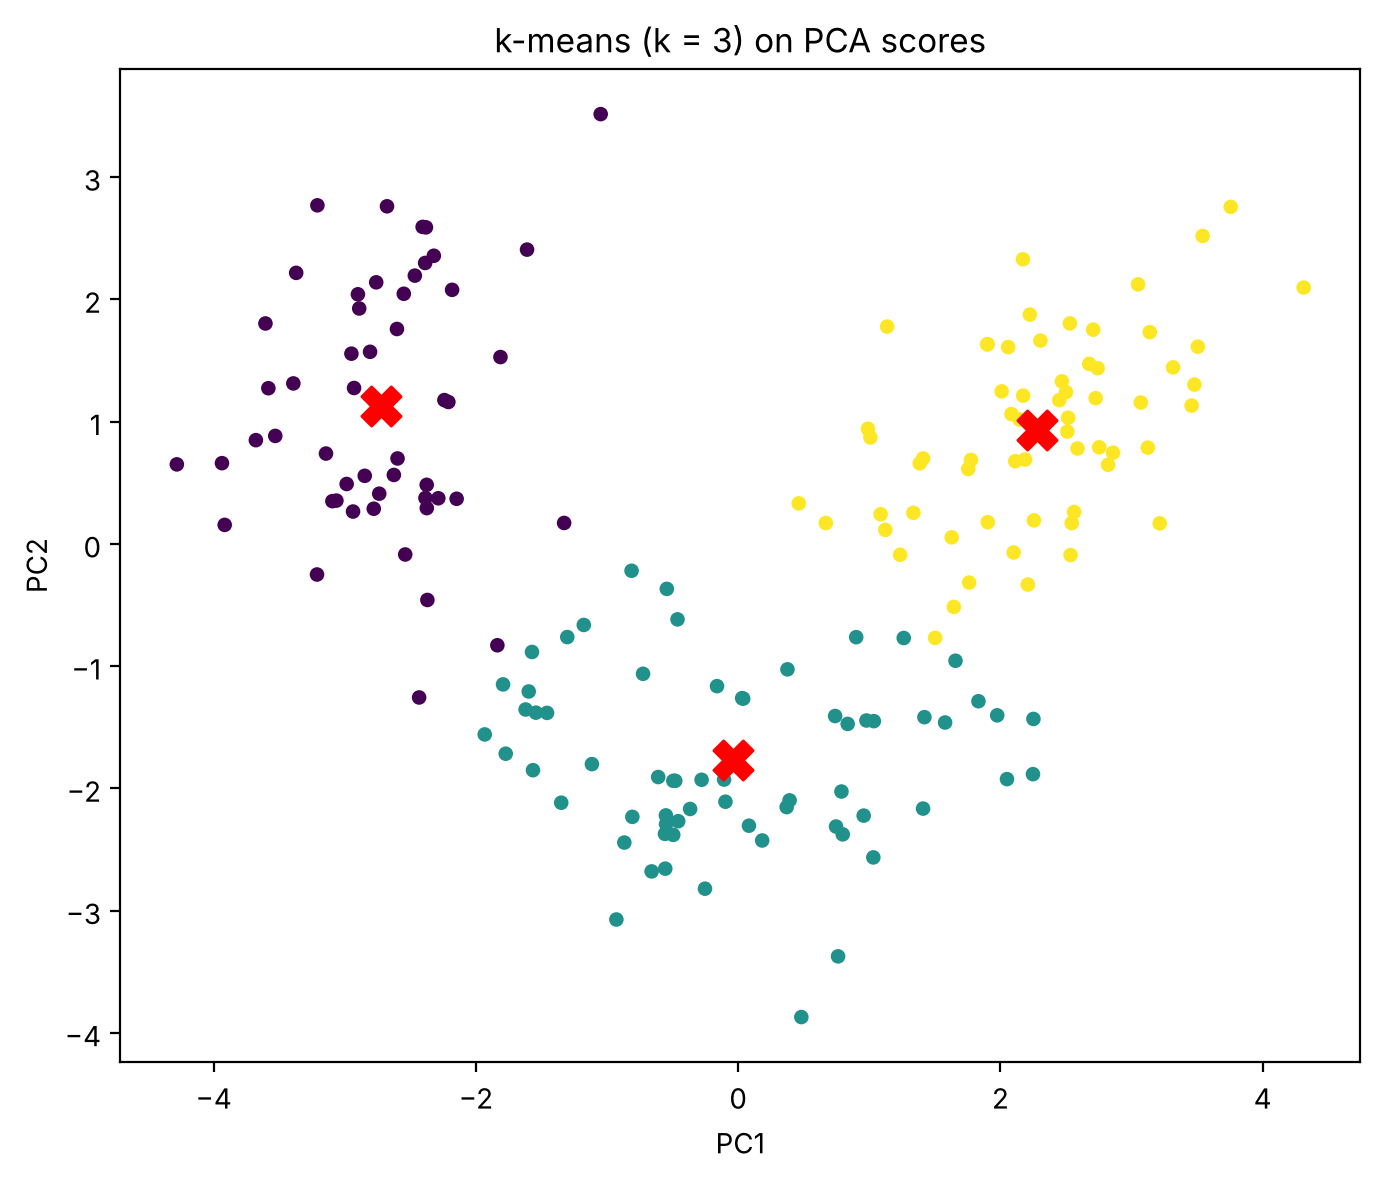

In [17]:
fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(scores[:, 0], scores[:, 1], c=lab_km, cmap='viridis', s=18)
ax.scatter(km3.cluster_centers_[:, 0], km3.cluster_centers_[:, 1], c='red', marker='X', s=200)
ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.set_title('k-means (k = 3) on PCA scores')
plt.tight_layout(); plt.show()

### 3.4 Hierarchical clustering on the same components

In [18]:
d = pdist(scores)
hc_res = {}
for m in ['complete', 'average', 'single', 'ward']:
    Zl = linkage(scores, method=m)
    lab = fcluster(Zl, t=3, criterion='maxclust')
    hc_res[m] = {'linkage': Zl, 'labels': lab}
    print(f"{m:>8}: cophenetic r = {cophenet(Zl, d)[0]:.3f} | sizes = {np.bincount(lab)[1:]} | "
          f"silhouette = {silhouette_score(scores, lab):.3f} | ARI vs k-means = {adjusted_rand_score(lab_km, lab):.3f}")

complete: cophenetic r = 0.543 | sizes = [ 23  48 107] | silhouette = 0.228 | ARI vs k-means = 0.481
 average: cophenetic r = 0.769 | sizes = [ 50 127   1] | silhouette = 0.318 | ARI vs k-means = 0.495
  single: cophenetic r = 0.531 | sizes = [176   1   1] | silhouette = 0.107 | ARI vs k-means = -0.002
    ward: cophenetic r = 0.691 | sizes = [55 65 58] | silhouette = 0.347 | ARI vs k-means = 0.827


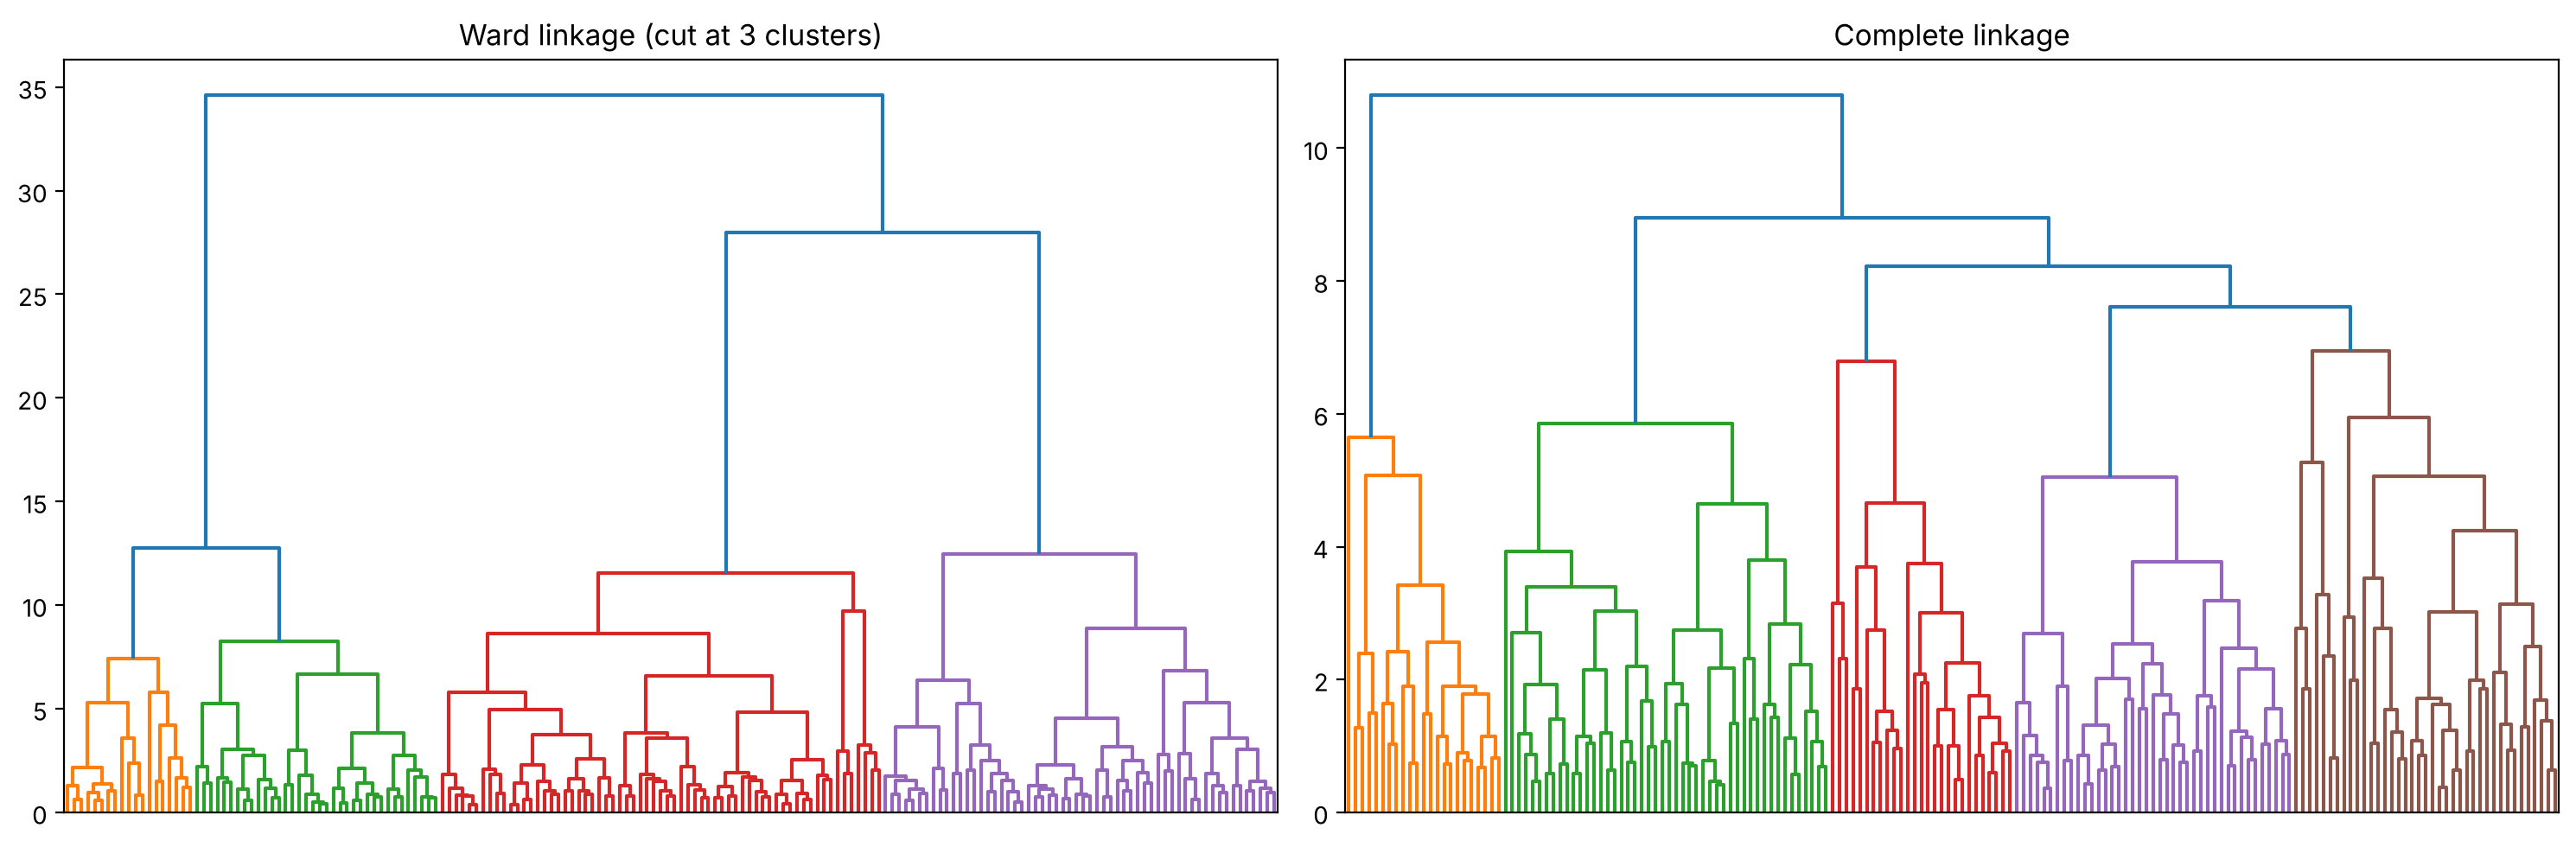

Ward      1   2   3
k-means            
0        49   0   2
1         6   3  56
2         0  62   0


In [19]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
dendrogram(hc_res['ward']['linkage'], no_labels=True, ax=ax[0], color_threshold=hc_res['ward']['linkage'][-3, 2])
ax[0].set_title('Ward linkage (cut at 3 clusters)')
dendrogram(hc_res['complete']['linkage'], no_labels=True, ax=ax[1]); ax[1].set_title('Complete linkage')
plt.tight_layout(); plt.show()
lab_hc = hc_res['ward']['labels']
print(pd.crosstab(lab_km, lab_hc, rownames=['k-means'], colnames=['Ward']))

### 3.5 Validation against the known cultivars (labels never used for fitting)

In [20]:
if cultivar is not None:
    print('ARI, k-means k=3 vs cultivar:', round(adjusted_rand_score(cultivar, lab_km), 3))
    print('ARI, Ward k=3 vs cultivar:', round(adjusted_rand_score(cultivar, lab_hc), 3))
    print(pd.crosstab(cultivar, lab_km, rownames=['cultivar'], colnames=['k-means']))
else:
    print('Labels not available for this file; skipping external validation.')

ARI, k-means k=3 vs cultivar: 0.897
ARI, Ward k=3 vs cultivar: 0.761
k-means    0   1   2
cultivar            
0          0   0  59
1          3  65   3
2         48   0   0


### 3.6 Interpretation

* **PCA.** Standardization was required because `Proline`'s variance (about 99,000) dwarfs every other variable. **Five components retain 80.2% of the total variance** (PC1 36.2%, PC2 19.2%, PC3 11.1%, PC4 7.1%, PC5 6.6%). PC1 is a phenolic axis: `Flavanoids` (+0.42), `Total_Phenols` (+0.39), `OD280` (+0.38), and `Proanthocyanins` (+0.31), set against `Nonflavanoid_Phenols` and `Malic_Acid`. PC2 is an intensity and body axis (`Color_Intensity` +0.53, `Alcohol` +0.48, `Proline` +0.36), and PC3 is an ash axis (`Ash` +0.63, `Ash_Alcanity` +0.61).
* **k-means.** Every criterion points to **k = 3**. The elbow bends there, and it has the highest average silhouette (0.369), the highest Calinski-Harabasz index (109.2), and the lowest Davies-Bouldin index (1.09). Larger k reduces within-cluster sum of squares only marginally while every quality index worsens. The k = 3 clusters are balanced (51, 65, and 62 wines) with similar spread, so k-means' assumption of compact, similar-sized clusters is reasonable. Twenty single random starts reached nearly the same objective (825.0 to 827.6), consistent with the local-optimum argument in Exercise 1.
* **Hierarchical clustering.** Ward linkage gives a balanced three-cluster solution (55, 65, 58) that closely matches k-means (adjusted Rand index 0.83). Average linkage has the highest cophenetic correlation (0.77), so its tree preserves the original distances best, but cut at three clusters it isolates a single outlying wine. Single linkage chains everything into one cluster of 176 wines, a known weakness. The linkage choice shapes the answer as much as the data does.
* **Substantive meaning.** The k-means profiles describe three chemical styles: (1) high-alcohol (13.7%), high-`Proline` (about 1,100), phenol-rich wines; (2) lower-alcohol (12.3%), lightly colored wines with moderate phenols; and (3) deeply colored, low-`Hue`, low-flavanoid wines with the highest `Malic_Acid`. Checked after the fact against the cultivar labels, which were never used for fitting, k-means recovers the three grape cultivars with an adjusted Rand index of 0.90 and Ward with 0.76. The unsupervised structure reflects real varietal differences rather than noise.
* **Limitations.** Most variables depart from normality, and 10 of 178 wines have at least one |z| > 3. The silhouette of 0.37 indicates moderately separated, partly overlapping clusters. k-means and Ward both favor spherical clusters, so boundary wines should be interpreted with caution.